# Classificação de tumores de mama: Naive Bayes × Árvore de Decisão × Random Forest

**Disciplina:** Ciência de Dados — Trabalho prático de classificação supervisionada em Python

**Integrantes:** _preencher com os nomes do grupo (até 5)_

**Problema:** prever se um tumor de mama é **maligno** ou **benigno** a partir de 30 medidas extraídas de imagens digitalizadas de biópsia por aspiração com agulha fina (PAAF).

**Objetivo:** comparar Naive Bayes, Árvore de Decisão e Random Forest em duas configurações — *baseline* (parâmetros padrão) e *ajustada* (busca sistemática de hiperparâmetros) — usando a mesma base, a mesma divisão treino/teste e a mesma semente, e decidir com base em evidências qual algoritmo é mais adequado.

### Roteiro do notebook
1. Configuração do ambiente e reprodutibilidade
2. Problema e base de dados
3. Análise exploratória (EDA)
4. Pré-processamento e protocolo experimental
5. Modelos *baseline*
6. Ajuste de hiperparâmetros
7. Comparação na validação cruzada
8. Avaliação final no conjunto de teste (usado uma única vez)
9. Interpretabilidade: árvore e importância das variáveis
10. Teste estatístico (Wilcoxon)
11. Discussão e conclusão

## 1. Configuração do ambiente e reprodutibilidade

In [1]:
import sys, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
from scipy.stats import wilcoxon

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV)
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay, confusion_matrix)

# Pastas do projeto (o notebook roda de dentro de notebooks/)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from avaliacao import (criar_pipeline, validar, resumo_cv,
                       treinar_cronometrado, metricas_teste,
                       formatar_media_dp)

DADOS = RAIZ / "dados"
RESULTADOS = RAIZ / "resultados"
FIGURAS = RESULTADOS / "figuras"
for p in (DADOS, RESULTADOS, FIGURAS):
    p.mkdir(parents=True, exist_ok=True)

# Semente única usada em TODA aleatoriedade do projeto
SEMENTE = 42
np.random.seed(SEMENTE)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def salvar(fig, nome):
    fig.savefig(FIGURAS / f"{nome}.png", dpi=150, bbox_inches="tight")

print(f"Python       {platform.python_version()}")
for lib in (np, pd, sklearn, matplotlib, sns, scipy):
    print(f"{lib.__name__:<12} {lib.__version__}")

Python       3.14.0
numpy        2.5.2
pandas       3.0.6
sklearn      1.9.0
matplotlib   3.11.1
seaborn      0.13.2
scipy        1.18.1


## 2. Problema e base de dados

**Por que este problema?** O câncer de mama é o tipo de câncer mais incidente entre mulheres no Brasil e no mundo (INCA; OMS). A PAAF é um exame rápido e barato, mas a leitura das lâminas depende do patologista. Um classificador que sinalize casos suspeitos pode servir de **apoio à decisão** (segunda opinião), nunca de substituto do médico.

**Base escolhida:** *Breast Cancer Wisconsin (Diagnostic)* — UCI Machine Learning Repository (Wolberg, Street & Mangasarian, 1995), distribuída também pelo scikit-learn (`load_breast_cancer`).
- 569 pacientes, 30 atributos numéricos contínuos, alvo binário (maligno/benigno).
- Cada imagem tem 10 características do núcleo celular (raio, textura, perímetro, área, suavidade, compacidade, concavidade, pontos côncavos, simetria e dimensão fractal), resumidas de três formas: **média** (`mean`), **erro padrão** (`error`) e **pior valor** (`worst`, média dos três maiores).
- Justificativa: base pública, documentada, citada na literatura, com rótulos confirmados por diagnóstico e atributos coerentes com o problema.

**Codificação do alvo:** no scikit-learn, `0 = maligno` e `1 = benigno`. Invertemos para **`1 = maligno` (classe positiva)**, porque é a classe de interesse: precisão, revocação e F1 passam a se referir diretamente à detecção do câncer.

In [2]:
base = load_breast_cancer(as_frame=True)
X = base.data.copy()
y = (1 - base.target).rename("maligno")     # 1 = maligno, 0 = benigno

df = X.assign(maligno=y)
df.to_csv(DADOS / "breast_cancer_wisconsin.csv", index=False)  # cópia local da base

print(f"Formato: {X.shape[0]} amostras × {X.shape[1]} atributos")
df.head()

Formato: 569 amostras × 30 atributos


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,maligno
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 3. Análise exploratória (EDA)

### 3.1 Tipos, estatísticas descritivas, ausentes e duplicados

In [3]:
print(X.dtypes.value_counts(), "\n")
print("Valores ausentes no total:", int(df.isna().sum().sum()))
print("Linhas duplicadas:       ", int(df.duplicated().sum()))
X.describe().T.round(3)

float64    30
Name: count, dtype: int64 

Valores ausentes no total: 0
Linhas duplicadas:        0


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


### 3.2 Proporção entre as classes

,n,proporção
maligno,,
Benigno,357,0.627
Maligno,212,0.373


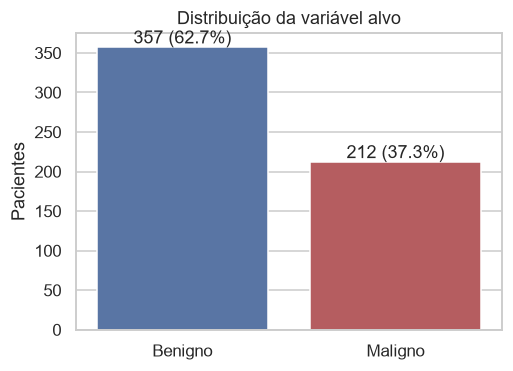

In [4]:
contagem = y.map({1: "Maligno", 0: "Benigno"}).value_counts()
proporcao = contagem / len(y)
display(pd.DataFrame({"n": contagem, "proporção": proporcao.round(3)}))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=contagem.index, y=contagem.values, hue=contagem.index,
            palette={"Benigno": "#4C72B0", "Maligno": "#C44E52"}, legend=False, ax=ax)
for i, v in enumerate(contagem.values):
    ax.text(i, v + 5, f"{v} ({v/len(y):.1%})", ha="center")
ax.set(title="Distribuição da variável alvo", xlabel="", ylabel="Pacientes")
salvar(fig, "01_distribuicao_classes"); plt.show()

### 3.3 Distribuição dos atributos por classe
As 10 características do grupo `mean` separadas por diagnóstico.

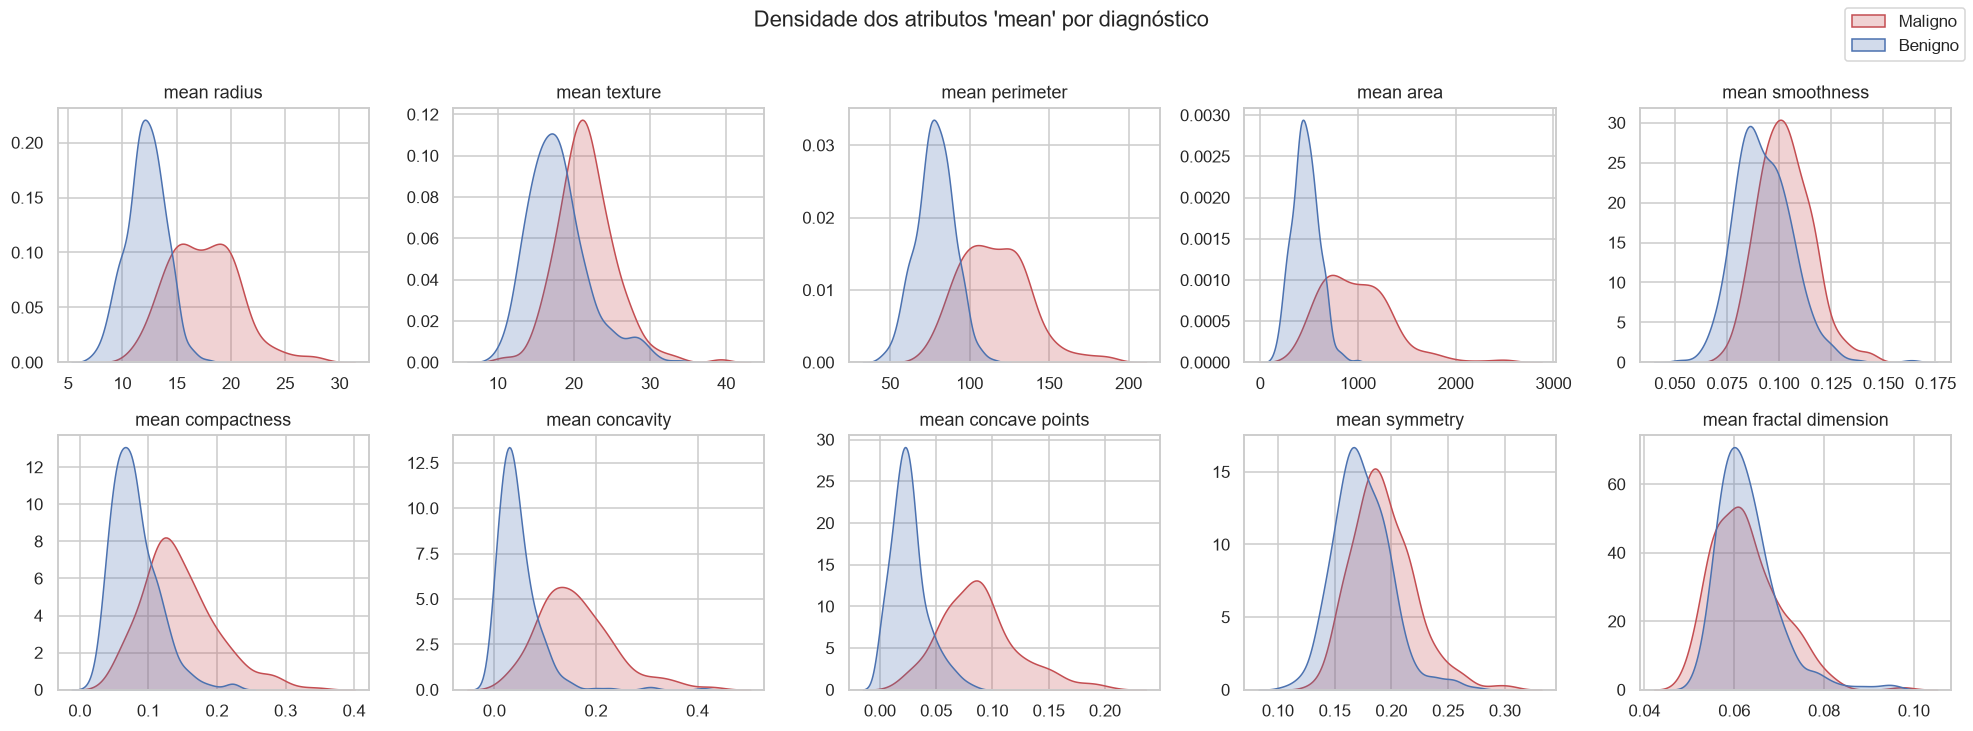

,assimetria
area error,5.45
concavity error,5.11
fractal dimension error,3.92
perimeter error,3.44
radius error,3.09
smoothness error,2.31
symmetry error,2.20
compactness error,1.90
worst area,1.86
worst fractal dimension,1.66


In [5]:
medias = [c for c in X.columns if c.startswith("mean")]
fig, axes = plt.subplots(2, 5, figsize=(18, 6.5))
for ax, col in zip(axes.ravel(), medias):
    sns.kdeplot(data=df, x=col, hue="maligno", fill=True, common_norm=False,
                palette={0: "#4C72B0", 1: "#C44E52"}, ax=ax, legend=False)
    ax.set(title=col, xlabel="", ylabel="")
fig.legend(["Maligno", "Benigno"], loc="upper right")
fig.suptitle("Densidade dos atributos 'mean' por diagnóstico", y=1.02)
fig.tight_layout(); salvar(fig, "02_distribuicoes_por_classe"); plt.show()

# Assimetria: muitos atributos têm cauda longa à direita
X.skew().sort_values(ascending=False).head(10).round(2).to_frame("assimetria")

### 3.4 Outliers (critério de 1,5 × IQR)

Pacientes com ao menos um atributo fora do IQR: 171 de 569


,n_outliers,% outliers,% malignos entre outliers
area error,65,11.4,100.0
radius error,38,6.7,97.4
perimeter error,38,6.7,100.0
worst area,35,6.2,100.0
smoothness error,30,5.3,13.3
fractal dimension error,28,4.9,35.7
compactness error,28,4.9,50.0
symmetry error,27,4.7,59.3
mean area,25,4.4,100.0
worst fractal dimension,24,4.2,75.0


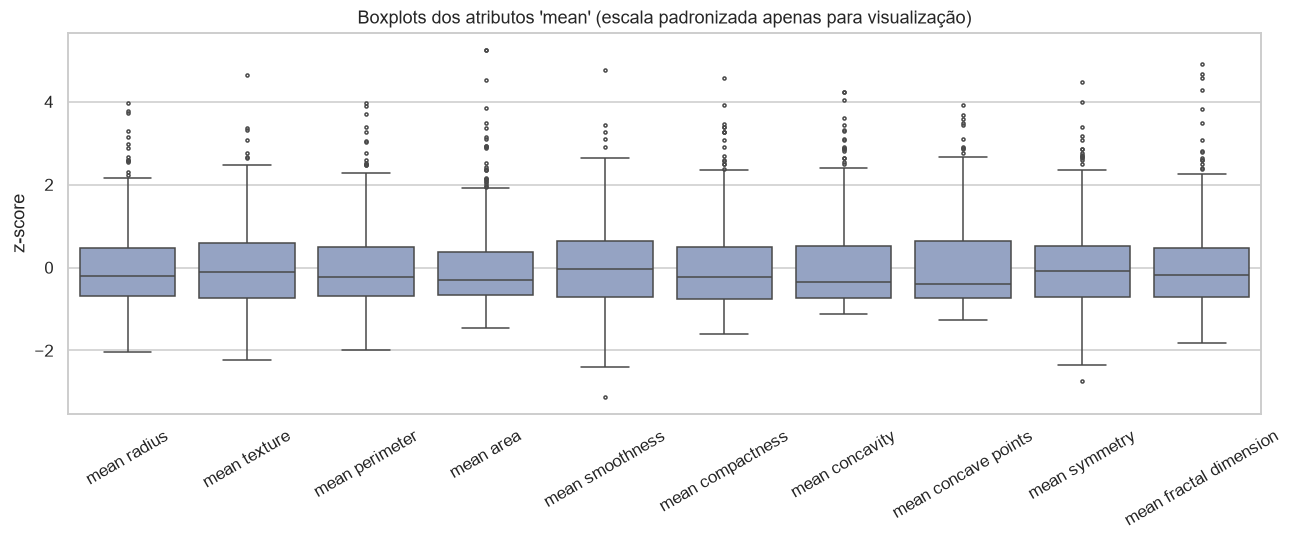

In [6]:
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
fora = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr))
outliers = pd.DataFrame({
    "n_outliers": fora.sum(),
    "% outliers": (fora.mean() * 100).round(1),
    "% malignos entre outliers": (fora.mul(y, axis=0).sum() / fora.sum().replace(0, np.nan) * 100).round(1),
}).sort_values("n_outliers", ascending=False)
print(f"Pacientes com ao menos um atributo fora do IQR: {fora.any(axis=1).sum()} de {len(X)}")
display(outliers.head(10))

fig, ax = plt.subplots(figsize=(14, 4.5))
z = (X[medias] - X[medias].mean()) / X[medias].std()   # só para visualizar na mesma escala
sns.boxplot(data=z, ax=ax, color="#8da0cb", fliersize=2)
ax.set(title="Boxplots dos atributos 'mean' (escala padronizada apenas para visualização)", ylabel="z-score")
ax.tick_params(axis="x", rotation=30)
salvar(fig, "03_boxplots_outliers"); plt.show()

### 3.5 Correlações

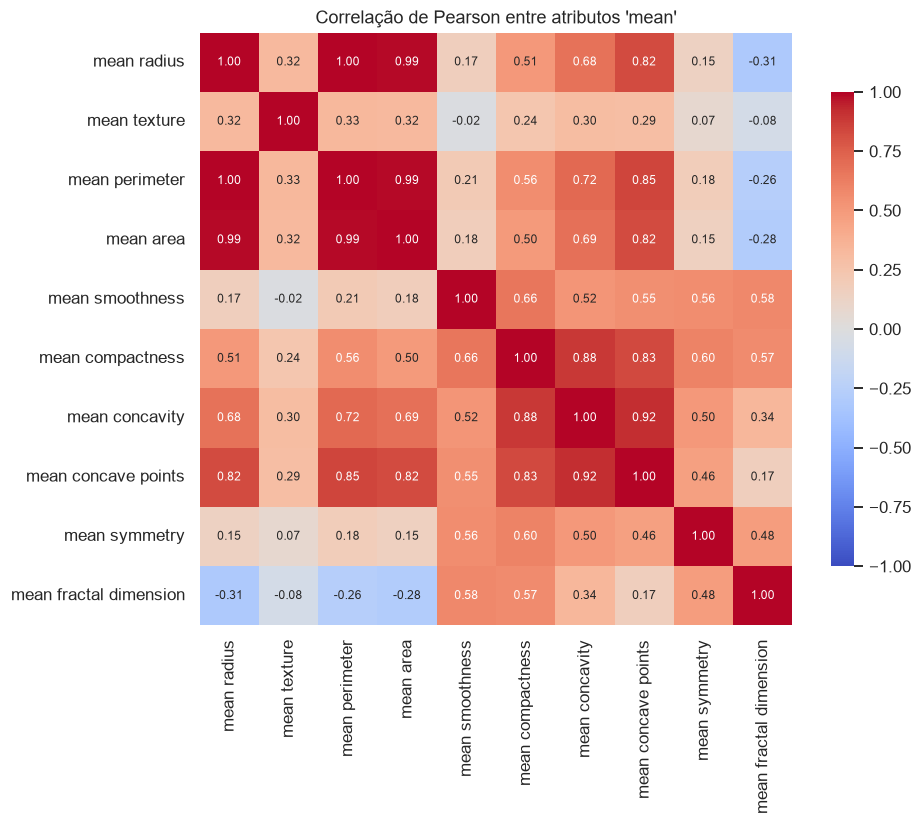

Pares com |r| > 0,9: 21 de 435


,,|r|
mean radius,mean perimeter,0.998
worst radius,worst perimeter,0.994
mean radius,mean area,0.987
mean perimeter,mean area,0.987
worst radius,worst area,0.984
worst perimeter,worst area,0.978
radius error,perimeter error,0.973
mean perimeter,worst perimeter,0.970


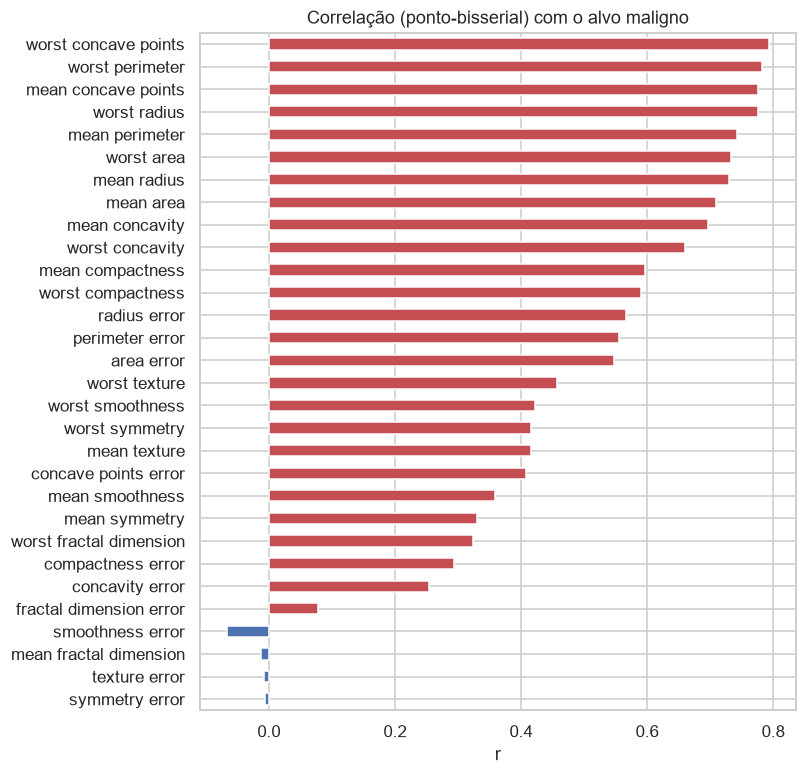

In [7]:
corr = X[medias].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, ax=ax, cbar_kws={"shrink": .8}, annot_kws={"size": 8})
ax.set_title("Correlação de Pearson entre atributos 'mean'")
salvar(fig, "04_correlacao"); plt.show()

# Pares muito correlacionados (|r| > 0,9) no conjunto completo de 30 atributos
c = X.corr().abs()
pares = (c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack()
           .dropna().sort_values(ascending=False))
print(f"Pares com |r| > 0,9: {(pares > 0.9).sum()} de {len(pares)}")
display(pares.head(8).round(3).to_frame("|r|"))

# Correlação de cada atributo com o alvo
corr_alvo = X.corrwith(y).sort_values(key=abs, ascending=False)
fig, ax = plt.subplots(figsize=(7, 8))
corr_alvo.plot.barh(ax=ax, color=np.where(corr_alvo > 0, "#C44E52", "#4C72B0"))
ax.invert_yaxis(); ax.set(title="Correlação (ponto-bisserial) com o alvo maligno", xlabel="r")
salvar(fig, "05_correlacao_alvo"); plt.show()

### 3.6 O que a análise exploratória mostrou (e como isso guia as decisões)

- **Qualidade:** 569 pacientes, 30 atributos `float64`, **nenhum valor ausente e nenhuma linha duplicada**. Não há variáveis categóricas.
- **Classes:** 357 benignos (62,7%) e 212 malignos (37,3%). Desbalanceamento **moderado**: um modelo que chutasse sempre "benigno" teria 62,7% de acurácia sem detectar nenhum câncer. Por isso usamos divisão estratificada e priorizamos F1 e revocação da classe maligno.
- **Poder de separação:** atributos de **tamanho** (raio, perímetro, área) e de **forma irregular** (concavidade, pontos côncavos) separam bem as classes — malignos são maiores e mais irregulares. Suavidade, simetria e dimensão fractal se sobrepõem bastante.
- **Assimetria:** os atributos do grupo `error` têm cauda longa à direita (assimetria até 5,4). Isso afeta o GaussianNB, que supõe distribuição normal dentro de cada classe.
- **Outliers:** 171 pacientes têm ao menos um valor fora de 1,5 × IQR, mas nos atributos de tamanho **100% desses outliers são malignos**. Eles são o próprio sinal da doença, não erro de medição → **mantidos**.
- **Multicolinearidade forte:** raio, perímetro e área têm r ≈ 0,99 entre si; 21 pares de atributos têm |r| > 0,9. Isso **viola a hipótese de independência condicional do Naive Bayes** (a mesma evidência é "contada" várias vezes). Para árvores, a correlação não prejudica a predição, mas divide a importância entre atributos redundantes.

## 4. Pré-processamento e protocolo experimental

| Decisão | Escolha | Justificativa |
|---|---|---|
| Divisão treino/teste | 70% / 30%, `stratify=y`, `random_state=42` | Mantém a proporção de malignos nos dois conjuntos; 30% (≈171 casos) dá um teste com ≈64 malignos, suficiente para estimar revocação |
| Validação cruzada | `StratifiedKFold(k=10, shuffle=True, random_state=42)` | Base pequena: k=10 usa 90% do treino em cada ajuste e dá 10 valores por modelo (média, desvio e teste de Wilcoxon) |
| Mesmo `cv` para todos | Um único objeto `cv` | Os seis modelos são avaliados **nos mesmos folds**, o que torna a comparação pareada e justa |
| Valores ausentes | `SimpleImputer(median)` dentro do Pipeline | Não há ausentes, mas o pipeline fica robusto; a mediana é calculada só com o treino de cada fold |
| Outliers | Mantidos | São medidas biológicas plausíveis e concentradas nos malignos — removê-los apagaria justamente o sinal da classe de interesse; árvores são robustas a eles |
| Variáveis categóricas | Não há | Todos os 30 atributos são contínuos |
| Padronização | **Não** usada nos 3 algoritmos obrigatórios | GaussianNB estima média/variância por atributo e árvores fazem cortes por limiar: ambos são invariantes à escala |
| Balanceamento | Sem SMOTE; `class_weight` testado como hiperparâmetro | Desbalanceamento moderado (≈37/63). Reamostrar criaria pacientes sintéticos; preferimos deixar a busca decidir se pesos de classe ajudam |
| Variante de Naive Bayes | `GaussianNB` | Atributos contínuos (medidas geométricas). `MultinomialNB` é para contagens e `CategoricalNB` para categorias |
| Métrica de ajuste | F1 da classe maligno | Equilibra precisão e revocação; acurácia sozinha esconde falsos negativos |

**Evitando vazamento de dados:** toda transformação está dentro de um `Pipeline`. Em `cross_validate` e `GridSearchCV`, o pipeline inteiro é reajustado em cada fold usando só a parte de treino daquele fold. O conjunto de teste não participa da EDA de decisão, do ajuste nem da escolha de hiperparâmetros: ele é usado **uma única vez**, na seção 8.

In [8]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEMENTE)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMENTE)

pd.DataFrame({
    "n": [len(y_treino), len(y_teste)],
    "malignos": [int(y_treino.sum()), int(y_teste.sum())],
    "% malignos": [round(y_treino.mean() * 100, 1), round(y_teste.mean() * 100, 1)],
}, index=["treino", "teste"])

,n,malignos,% malignos
treino,398,148,37.2
teste,171,64,37.4


## 5. Modelos *baseline* (parâmetros padrão)

Cada algoritmo é usado com os parâmetros padrão do scikit-learn. Apenas `random_state` é fixado na árvore e na floresta, para que o resultado seja reprodutível (isso não altera o algoritmo, só fixa o sorteio).

In [9]:
baselines = {
    "NB baseline": criar_pipeline(GaussianNB()),
    "AD baseline": criar_pipeline(DecisionTreeClassifier(random_state=SEMENTE)),
    "RF baseline": criar_pipeline(RandomForestClassifier(random_state=SEMENTE)),
}

folds = {}
for nome, modelo in baselines.items():
    folds[nome] = validar(modelo, X_treino, y_treino, cv)
    print(f"{nome:<12} F1 = {folds[nome]['f1'].mean():.3f} ± {folds[nome]['f1'].std(ddof=1):.3f}")

NB baseline  F1 = 0.916 ± 0.074


AD baseline  F1 = 0.885 ± 0.063


RF baseline  F1 = 0.939 ± 0.064


## 6. Ajuste de hiperparâmetros (`GridSearchCV`, somente no treino)

| Algoritmo | Hiperparâmetro | O que controla | Valores testados |
|---|---|---|---|
| Naive Bayes | `var_smoothing` | Fração da maior variância somada a todas as variâncias; suaviza gaussianas muito “estreitas” e estabiliza a estimativa | 10⁻¹² a 10⁰ (25 valores em escala log) |
| Árvore | `criterion` | Medida de impureza usada para escolher os cortes | gini, entropy |
|  | `max_depth` | Profundidade máxima (limita a complexidade) | None, 3, 4, 5, 6, 8 |
|  | `min_samples_leaf` | Mínimo de amostras por folha (evita folhas com 1 paciente) | 1, 2, 4, 8 |
|  | `ccp_alpha` | Poda por custo-complexidade | 0, 0,005, 0,01, 0,02 |
|  | `class_weight` | Peso maior para a classe minoritária | None, balanced |
| Random Forest | `n_estimators` | Número de árvores | 200, 500 |
|  | `max_depth` | Profundidade de cada árvore | None, 6, 10 |
|  | `max_features` | Atributos sorteados em cada corte (descorrelaciona as árvores) | sqrt, log2, 0,3 |
|  | `min_samples_leaf` | Mínimo por folha | 1, 3 |
|  | `class_weight` | Pesos de classe por amostra bootstrap | None, balanced_subsample |

A busca é **exaustiva** (Grid) porque a base é pequena e o custo cabe no orçamento; o critério de escolha é o F1 médio nos mesmos 10 folds.

In [10]:
grades = {
    "NB": (GaussianNB(),
           {"modelo__var_smoothing": np.logspace(-12, 0, 25)}),
    "AD": (DecisionTreeClassifier(random_state=SEMENTE),
           {"modelo__criterion": ["gini", "entropy"],
            "modelo__max_depth": [None, 3, 4, 5, 6, 8],
            "modelo__min_samples_leaf": [1, 2, 4, 8],
            "modelo__ccp_alpha": [0.0, 0.005, 0.01, 0.02],
            "modelo__class_weight": [None, "balanced"]}),
    "RF": (RandomForestClassifier(random_state=SEMENTE),
           {"modelo__n_estimators": [200, 500],
            "modelo__max_depth": [None, 6, 10],
            "modelo__max_features": ["sqrt", "log2", 0.3],
            "modelo__min_samples_leaf": [1, 3],
            "modelo__class_weight": [None, "balanced_subsample"]}),
}

buscas, tempo_busca = {}, {}
for sigla, (clf, grade) in grades.items():
    busca = GridSearchCV(criar_pipeline(clf), grade, cv=cv, scoring="f1",
                         n_jobs=-1, refit=True)
    tempo_busca[sigla] = treinar_cronometrado(busca, X_treino, y_treino)
    buscas[sigla] = busca
    n_comb = len(busca.cv_results_["params"])
    print(f"{sigla}: {n_comb} combinações × 10 folds em {tempo_busca[sigla]:.1f}s | "
          f"melhor F1 CV = {busca.best_score_:.3f}")
    print("    ", {k.replace('modelo__', ''): v for k, v in busca.best_params_.items()})

ajustados = {f"{s} ajustado": b.best_estimator_ for s, b in buscas.items()}

NB: 25 combinações × 10 folds em 1.1s | melhor F1 CV = 0.917
     {'var_smoothing': np.float64(3.1622776601683795e-10)}


AD: 384 combinações × 10 folds em 43.9s | melhor F1 CV = 0.911
     {'ccp_alpha': 0.01, 'class_weight': None, 'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1}


RF: 72 combinações × 10 folds em 164.8s | melhor F1 CV = 0.949
     {'class_weight': 'balanced_subsample', 'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 1, 'n_estimators': 500}


Para que a comparação baseline × ajustado seja **pareada**, os modelos ajustados são reavaliados com `cross_validate` nos mesmos 10 folds.

> **Atenção (viés otimista):** os hiperparâmetros foram escolhidos olhando para esses mesmos folds, então a média de CV dos ajustados tende a ser levemente otimista. Por isso o veredito final vem do conjunto de teste, que nunca foi visto. Uma validação cruzada aninhada (*nested CV*) eliminaria esse viés, ao custo de ~10× mais tempo.

In [11]:
for nome, modelo in ajustados.items():
    folds[nome] = validar(modelo, X_treino, y_treino, cv)

# Distribuição do F1 de todas as combinações testadas (sensibilidade aos hiperparâmetros)
sens = pd.DataFrame({s: pd.Series(b.cv_results_["mean_test_score"]).describe()[["min", "50%", "max"]]
                     for s, b in buscas.items()}).T.round(3)
sens.columns = ["F1 pior combinação", "F1 mediano", "F1 melhor combinação"]
sens

,F1 pior combinação,F1 mediano,F1 melhor combinação
NB,0.684,0.890,0.917
AD,0.851,0.884,0.911
RF,0.921,0.929,0.949


## 7. Comparação na validação cruzada (média ± desvio padrão, 10 folds)

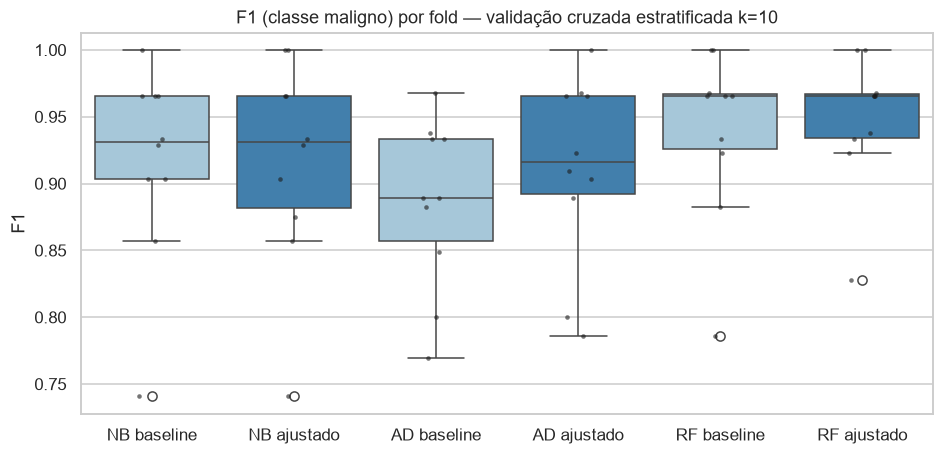

,acuracia,precisao,revocacao,f1,auc
NB baseline,0.940 ± 0.050,0.931 ± 0.067,0.906 ± 0.096,0.916 ± 0.074,0.984 ± 0.016
NB ajustado,0.940 ± 0.054,0.932 ± 0.077,0.906 ± 0.096,0.917 ± 0.079,0.983 ± 0.017
AD baseline,0.915 ± 0.044,0.881 ± 0.065,0.898 ± 0.106,0.885 ± 0.063,0.911 ± 0.053
AD ajustado,0.934 ± 0.052,0.923 ± 0.091,0.904 ± 0.087,0.911 ± 0.071,0.931 ± 0.059
RF baseline,0.955 ± 0.047,0.951 ± 0.076,0.932 ± 0.084,0.939 ± 0.064,0.981 ± 0.021
RF ajustado,0.962 ± 0.036,0.961 ± 0.055,0.939 ± 0.068,0.949 ± 0.050,0.987 ± 0.016


In [12]:
ordem = ["NB baseline", "NB ajustado", "AD baseline", "AD ajustado", "RF baseline", "RF ajustado"]
cv_resumo = resumo_cv(folds).loc[ordem]
tabela_cv = pd.DataFrame({m: formatar_media_dp(cv_resumo, m)
                          for m in ["acuracia", "precisao", "revocacao", "f1", "auc"]})
tabela_cv

fig, ax = plt.subplots(figsize=(10, 4.5))
dados_box = pd.DataFrame({n: folds[n]["f1"] for n in ordem})
sns.boxplot(data=dados_box, ax=ax, palette=["#9ecae1", "#3182bd"] * 3)
sns.stripplot(data=dados_box, ax=ax, color="k", size=3, alpha=.6)
ax.set(title="F1 (classe maligno) por fold — validação cruzada estratificada k=10", ylabel="F1")
salvar(fig, "06_cv_boxplot_f1"); plt.show()
tabela_cv

## 8. Avaliação final no conjunto de teste (usado uma única vez)

Cada um dos seis pipelines é treinado no treino completo (o tempo é cronometrado) e avaliado **uma vez** no teste. Nenhuma decisão de modelagem é tomada depois disso.

In [13]:
modelos = {**baselines, **ajustados}
teste, tempo_treino = {}, {}
for nome in ordem:
    tempo_treino[nome] = treinar_cronometrado(modelos[nome], X_treino, y_treino)
    teste[nome] = metricas_teste(modelos[nome], X_teste, y_teste)

teste_df = pd.DataFrame(teste).T.loc[ordem]
teste_df.round(3)

,acuracia,precisao,revocacao,f1,auc
NB baseline,0.936,0.982,0.844,0.908,0.996
NB ajustado,0.947,0.982,0.875,0.926,0.995
AD baseline,0.901,0.885,0.844,0.864,0.889
AD ajustado,0.936,0.982,0.844,0.908,0.928
RF baseline,0.965,1.000,0.906,0.951,0.997
RF ajustado,0.977,1.000,0.938,0.968,0.997


### 8.1 Tabela final — os seis modelos lado a lado (Apêndice do relatório)

In [14]:
tabela_final = pd.DataFrame(index=ordem)
tabela_final["F1 CV (média ± dp)"] = formatar_media_dp(cv_resumo, "f1")
tabela_final["Revocação CV (média ± dp)"] = formatar_media_dp(cv_resumo, "revocacao")
tabela_final["Acurácia CV (média ± dp)"] = formatar_media_dp(cv_resumo, "acuracia")
for m, rot in [("acuracia", "Acurácia teste"), ("precisao", "Precisão teste"),
               ("revocacao", "Revocação teste"), ("f1", "F1 teste"), ("auc", "AUC teste")]:
    tabela_final[rot] = teste_df[m].round(3)
cm = {n: confusion_matrix(y_teste, modelos[n].predict(X_teste), labels=[1, 0]) for n in ordem}
tabela_final["FN teste"] = [cm[n][0, 1] for n in ordem]
tabela_final["FP teste"] = [cm[n][1, 0] for n in ordem]
tabela_final["Tempo treino (s)"] = [round(tempo_treino[n], 3) for n in ordem]
tabela_final["Tempo busca (s)"] = ["—", round(tempo_busca["NB"], 1), "—", round(tempo_busca["AD"], 1),
                                   "—", round(tempo_busca["RF"], 1)]
tabela_final.to_csv(RESULTADOS / "tabela_final_seis_modelos.csv", encoding="utf-8-sig")
cv_resumo.to_csv(RESULTADOS / "cv_resumo.csv", encoding="utf-8-sig")
teste_df.to_csv(RESULTADOS / "metricas_teste.csv", encoding="utf-8-sig")
tabela_final

,F1 CV (média ± dp),Revocação CV (média ± dp),Acurácia CV (média ± dp),Acurácia teste,Precisão teste,Revocação teste,F1 teste,AUC teste,FN teste,FP teste,Tempo treino (s),Tempo busca (s)
NB baseline,0.916 ± 0.074,0.906 ± 0.096,0.940 ± 0.050,0.936,0.982,0.844,0.908,0.996,10,1,0.007,—
NB ajustado,0.917 ± 0.079,0.906 ± 0.096,0.940 ± 0.054,0.947,0.982,0.875,0.926,0.995,8,1,0.005,1.1
AD baseline,0.885 ± 0.063,0.898 ± 0.106,0.915 ± 0.044,0.901,0.885,0.844,0.864,0.889,10,7,0.010,—
AD ajustado,0.911 ± 0.071,0.904 ± 0.087,0.934 ± 0.052,0.936,0.982,0.844,0.908,0.928,10,1,0.010,43.9
RF baseline,0.939 ± 0.064,0.932 ± 0.084,0.955 ± 0.047,0.965,1.000,0.906,0.951,0.997,6,0,0.213,—
RF ajustado,0.949 ± 0.050,0.939 ± 0.068,0.962 ± 0.036,0.977,1.000,0.938,0.968,0.997,4,0,1.404,164.8


### 8.2 Relatórios de classificação

In [15]:
for nome in ordem:
    print(f"===== {nome} =====")
    print(classification_report(y_teste, modelos[nome].predict(X_teste),
                                target_names=["Benigno (0)", "Maligno (1)"], digits=3))

===== NB baseline =====
              precision    recall  f1-score   support

 Benigno (0)      0.914     0.991     0.951       107
 Maligno (1)      0.982     0.844     0.908        64

    accuracy                          0.936       171
   macro avg      0.948     0.917     0.929       171
weighted avg      0.939     0.936     0.935       171

===== NB ajustado =====
              precision    recall  f1-score   support

 Benigno (0)      0.930     0.991     0.959       107
 Maligno (1)      0.982     0.875     0.926        64

    accuracy                          0.947       171
   macro avg      0.956     0.933     0.942       171
weighted avg      0.950     0.947     0.947       171

===== AD baseline =====
              precision    recall  f1-score   support

 Benigno (0)      0.909     0.935     0.922       107
 Maligno (1)      0.885     0.844     0.864        64

    accuracy                          0.901       171
   macro avg      0.897     0.889     0.893       171
we

### 8.3 Matrizes de confusão
Linhas = classe real, colunas = classe prevista, com **Maligno (positivo) primeiro**, no mesmo formato da Tabela 1 do enunciado (`labels=[1, 0]`).

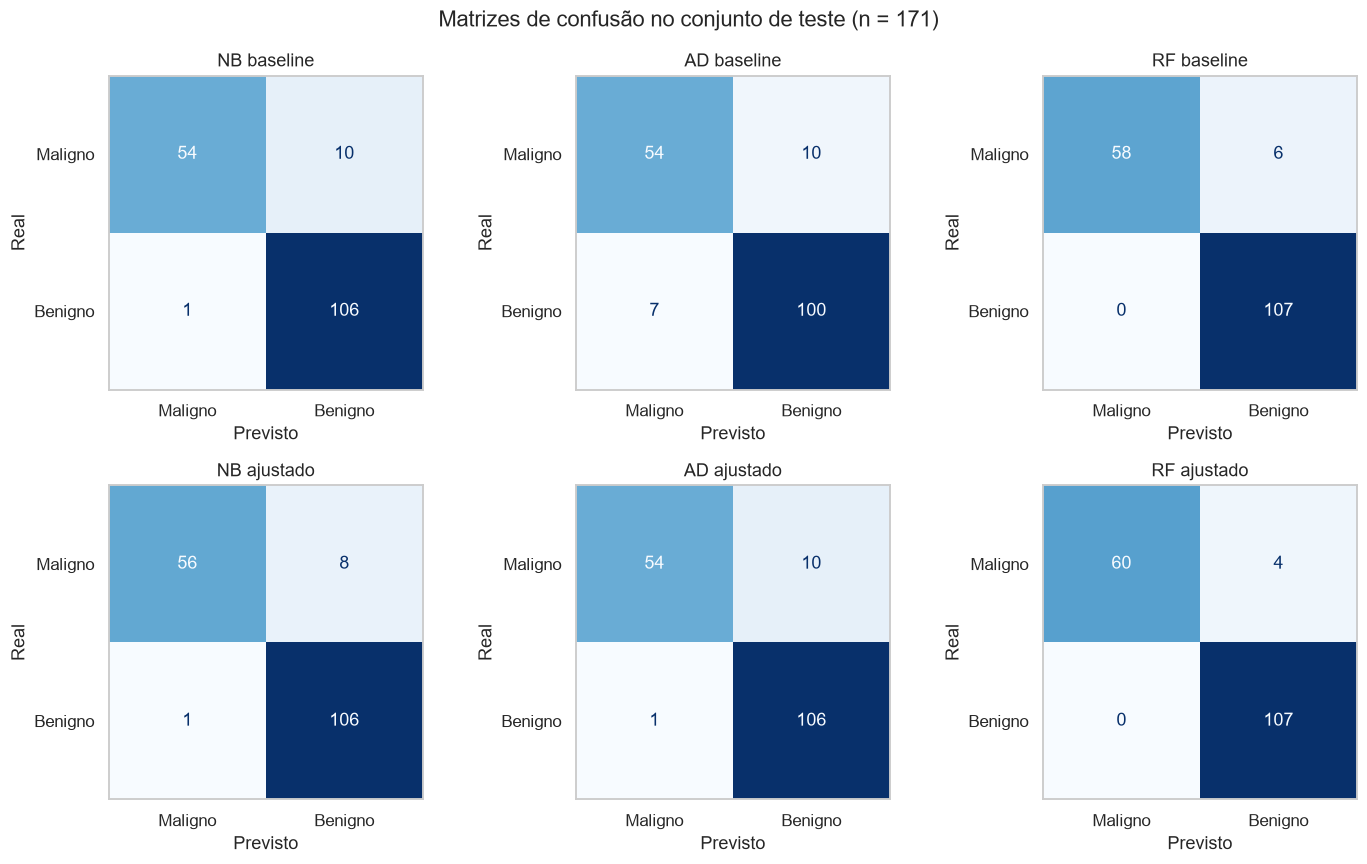

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, nome in zip(axes.T.ravel(), ordem):
    ConfusionMatrixDisplay.from_estimator(
        modelos[nome], X_teste, y_teste, labels=[1, 0],
        display_labels=["Maligno", "Benigno"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(nome); ax.set_xlabel("Previsto"); ax.set_ylabel("Real"); ax.grid(False)
fig.suptitle("Matrizes de confusão no conjunto de teste (n = 171)")
fig.tight_layout(); salvar(fig, "07_matrizes_confusao"); plt.show()

### 8.4 Curvas ROC no mesmo gráfico

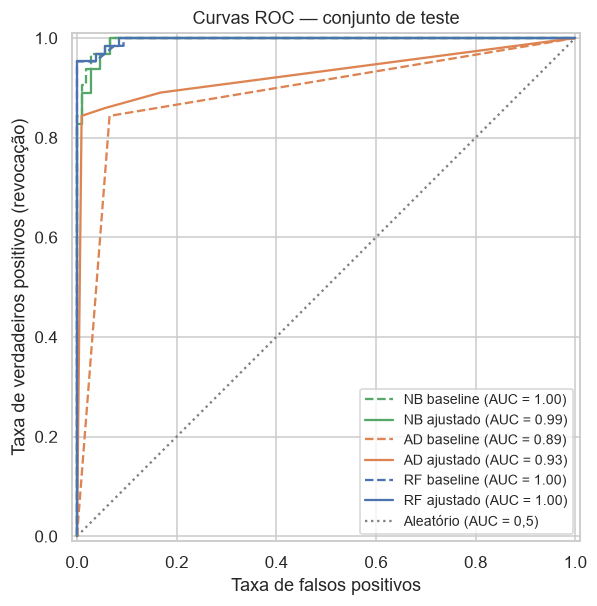

In [17]:
cores = {"NB": "#55A868", "AD": "#DD8452", "RF": "#4C72B0"}
fig, ax = plt.subplots(figsize=(7, 6))
for nome in ordem:
    RocCurveDisplay.from_estimator(modelos[nome], X_teste, y_teste, ax=ax, name=nome,
                                   curve_kwargs={"color": cores[nome[:2]],
                                                 "linestyle": "--" if "baseline" in nome else "-"})
ax.plot([0, 1], [0, 1], ":", color="gray", label="Aleatório (AUC = 0,5)")
ax.set(title="Curvas ROC — conjunto de teste", xlabel="Taxa de falsos positivos",
       ylabel="Taxa de verdadeiros positivos (revocação)")
ax.legend(loc="lower right", fontsize=9)
salvar(fig, "08_curvas_roc"); plt.show()

### 8.5 Comparação visual: CV × teste e tempo de treinamento

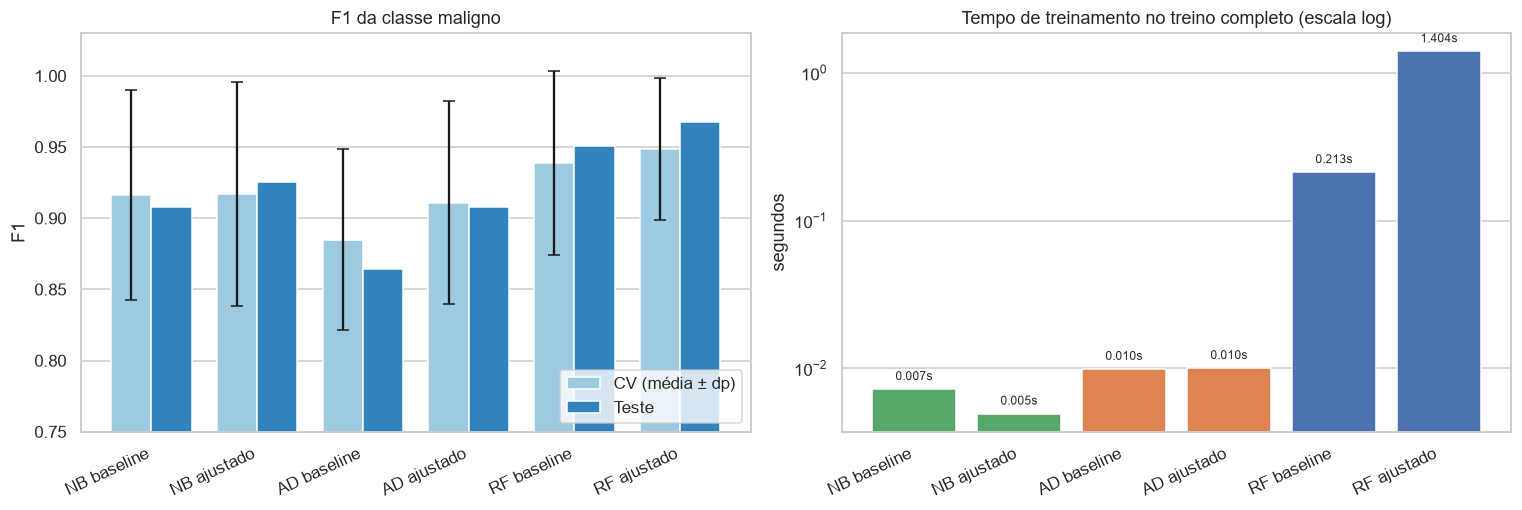

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
pos = np.arange(len(ordem)); larg = 0.38
ax1.bar(pos - larg/2, cv_resumo["f1_media"], larg, yerr=cv_resumo["f1_dp"], capsize=4,
        label="CV (média ± dp)", color="#9ecae1")
ax1.bar(pos + larg/2, teste_df["f1"], larg, label="Teste", color="#3182bd")
ax1.set_xticks(pos, ordem, rotation=25, ha="right"); ax1.set_ylim(0.75, 1.03); ax1.grid(axis="x", visible=False)
ax1.set(title="F1 da classe maligno", ylabel="F1"); ax1.legend(loc="lower right")

ax2.bar(pos, [tempo_treino[n] for n in ordem], color=[cores[n[:2]] for n in ordem])
ax2.set_xticks(pos, ordem, rotation=25, ha="right"); ax2.set_yscale("log"); ax2.grid(axis="x", visible=False)
ax2.set(title="Tempo de treinamento no treino completo (escala log)", ylabel="segundos")
for p, n in zip(pos, ordem):
    ax2.text(p, tempo_treino[n] * 1.15, f"{tempo_treino[n]:.3f}s", ha="center", fontsize=8)
fig.tight_layout(); salvar(fig, "09_comparacao_f1_tempo"); plt.show()

## 9. Interpretabilidade

### 9.1 Árvore de decisão ajustada e suas regras

Profundidade: 6 | folhas: 12
(baseline: profundidade 8, folhas 19)

|--- worst perimeter <= 112.80
|   |--- worst concave points <= 0.18
|   |   |--- mean texture <= 21.32
|   |   |   |--- area error <= 35.26
|   |   |   |   |--- class: 0
|   |   |   |--- area error >  35.26
|   |   |   |   |--- class: 0
|   |   |--- mean texture >  21.32
|   |   |   |--- mean concave points <= 0.05
|   |   |   |   |--- mean area <= 696.25
|   |   |   |   |   |--- texture error <= 0.86
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- texture error >  0.86
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |--- mean area >  696.25
|   |   |   |   |   |--- class: 1
|   |   |   |--- mean concave points >  0.05
|   |   |   |   |--- class: 1
|   |--- worst concave points >  0.18
|   |   |--- class: 1
|--- worst perimeter >  112.80
|   |--- worst concave points <= 0.14
|   |   |--- worst texture <= 21.85
|   |   |   |--- class: 0
|   |   |--- worst texture >  21.85
|   |   |   |--- worst per

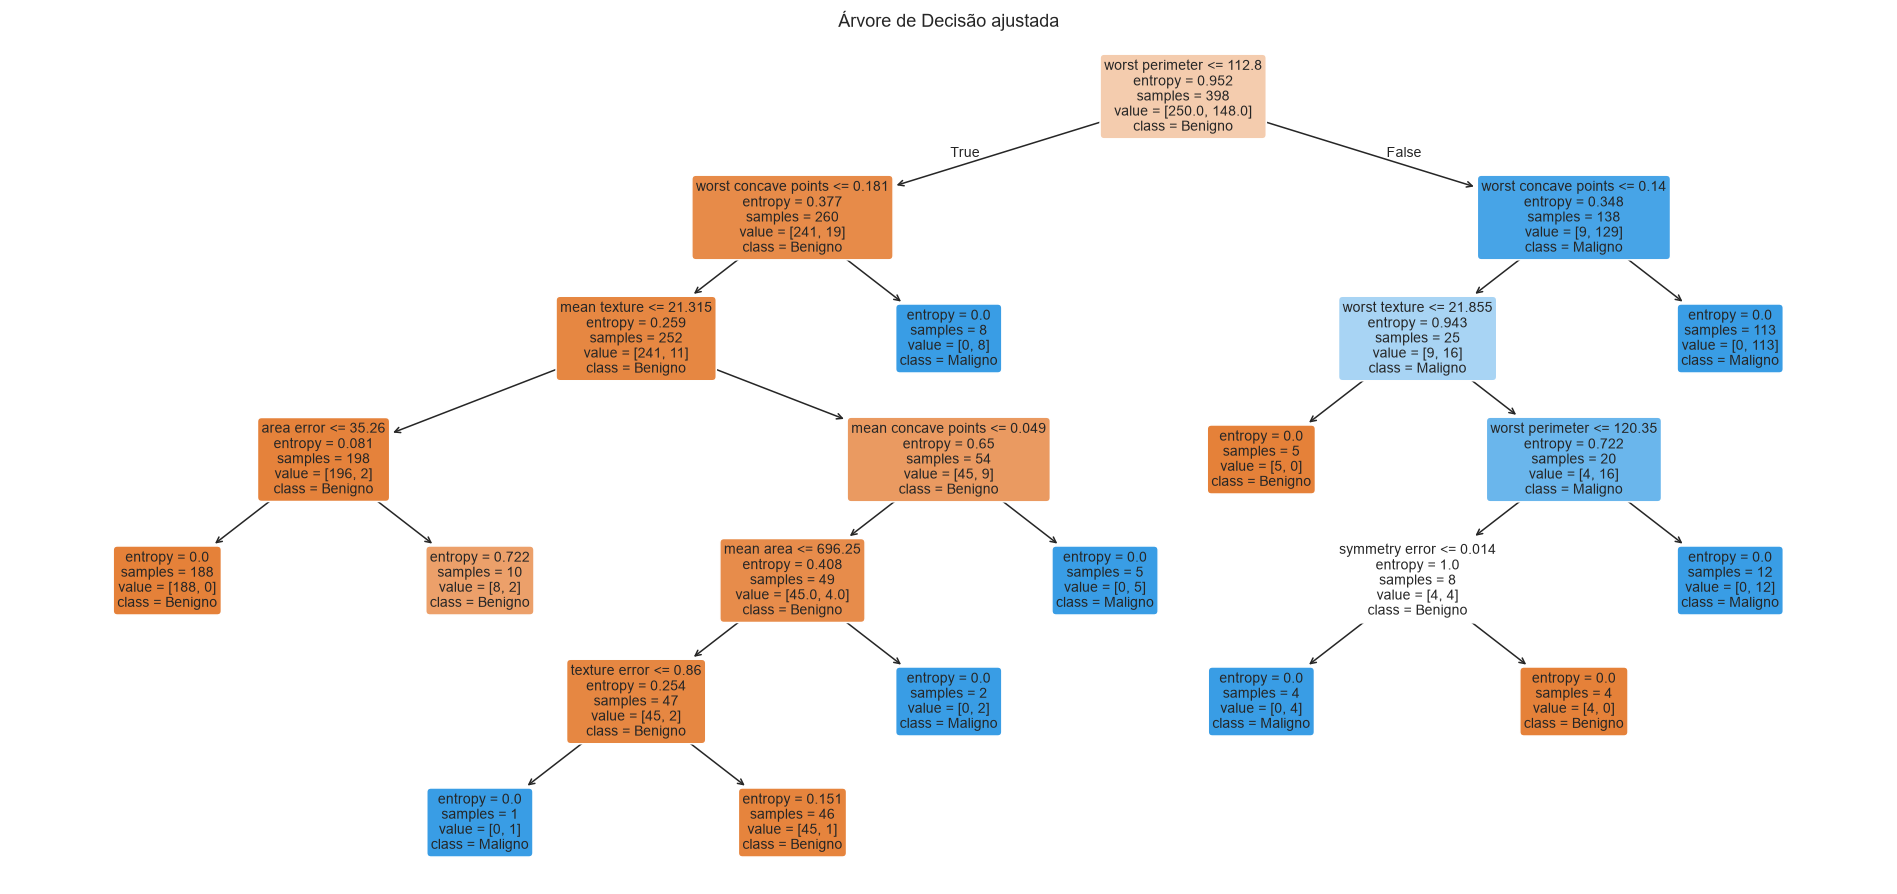

In [19]:
arvore = modelos["AD ajustado"].named_steps["modelo"]
print(f"Profundidade: {arvore.get_depth()} | folhas: {arvore.get_n_leaves()}")
print(f"(baseline: profundidade {modelos['AD baseline'].named_steps['modelo'].get_depth()}, "
      f"folhas {modelos['AD baseline'].named_steps['modelo'].get_n_leaves()})\n")
print(export_text(arvore, feature_names=list(X.columns), decimals=2))

fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(arvore, feature_names=X.columns, class_names=["Benigno", "Maligno"],
          filled=True, rounded=True, impurity=True, proportion=False, fontsize=9, ax=ax)
ax.set_title("Árvore de Decisão ajustada")
salvar(fig, "10_arvore_decisao"); plt.show()

### 9.2 Importância das variáveis (impureza × permutação)

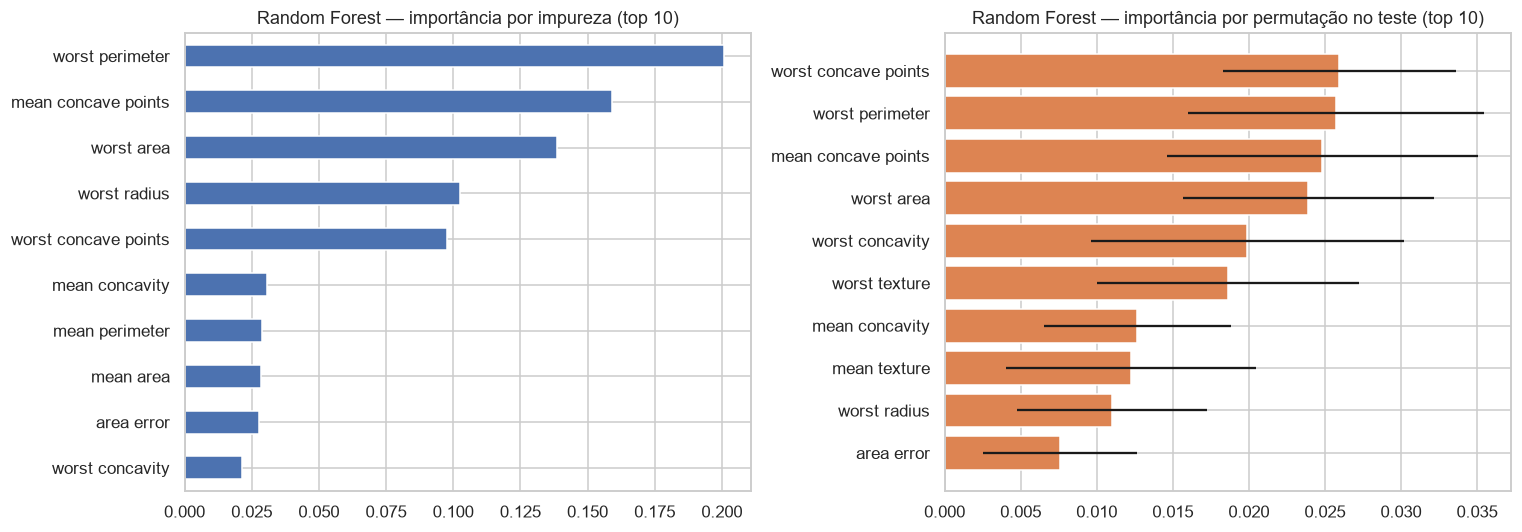

,RF (impureza),"RF (permutação, ΔF1)",AD (impureza)
worst perimeter,0.2009,0.0257,0.6560
mean concave points,0.1592,0.0248,0.0414
worst area,0.1388,0.0239,0.0000
worst radius,0.1025,0.0110,0.0000
worst concave points,0.0978,0.0259,0.1571
mean concavity,0.0308,0.0127,0.0000
mean perimeter,0.0288,0.0003,0.0000
mean area,0.0286,0.0003,0.0221
area error,0.0279,0.0076,0.0244
worst concavity,0.0214,0.0199,0.0000


In [20]:
rf = modelos["RF ajustado"].named_steps["modelo"]
imp_gini = pd.Series(rf.feature_importances_, index=X.columns)

# Importância por permutação: queda do F1 ao embaralhar cada atributo.
# Calculada após a avaliação final, só para interpretar (não altera o modelo).
perm = permutation_importance(modelos["RF ajustado"], X_teste, y_teste, scoring="f1",
                              n_repeats=30, random_state=SEMENTE, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=X.columns)
imp_ad = pd.Series(arvore.feature_importances_, index=X.columns)

importancias = pd.DataFrame({"RF (impureza)": imp_gini, "RF (permutação, ΔF1)": imp_perm,
                             "AD (impureza)": imp_ad})
top = importancias.sort_values("RF (impureza)", ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top["RF (impureza)"].sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Random Forest — importância por impureza (top 10)")
p = importancias["RF (permutação, ΔF1)"].sort_values(ascending=False).head(10)
axes[1].barh(p.index[::-1], p.values[::-1],
             xerr=pd.Series(perm.importances_std, index=X.columns)[p.index[::-1]], color="#DD8452")
axes[1].set_title("Random Forest — importância por permutação no teste (top 10)")
fig.tight_layout(); salvar(fig, "11_importancia_variaveis"); plt.show()
importancias.sort_values("RF (impureza)", ascending=False).head(10).round(4)

## 10. Teste estatístico: Wilcoxon pareado nos 10 folds

Hipótese nula (H₀): a mediana da diferença de F1 entre os dois modelos, fold a fold, é zero. Como os modelos foram avaliados **nos mesmos folds**, as amostras são pareadas. Nível de significância α = 0,05.

> **Limitação:** com 10 folds o teste tem pouco poder, e os folds compartilham dados de treino (não são totalmente independentes). O p-valor deve ser lido como indicação, junto com o tamanho da diferença.

In [21]:
comparacoes = [("NB baseline", "NB ajustado"), ("AD baseline", "AD ajustado"),
               ("RF baseline", "RF ajustado"), ("NB ajustado", "RF ajustado"),
               ("AD ajustado", "RF ajustado"), ("NB ajustado", "AD ajustado")]
linhas = []
for a, b in comparacoes:
    fa, fb = folds[a]["f1"], folds[b]["f1"]
    dif = fb - fa
    if np.allclose(dif, 0):
        p = 1.0
    else:
        p = wilcoxon(fa, fb, zero_method="zsplit").pvalue
    linhas.append({"modelo A": a, "modelo B": b, "F1 médio A": fa.mean(), "F1 médio B": fb.mean(),
                   "diferença média (B−A)": dif.mean(), "folds B > A": int((dif > 0).sum()),
                   "p-valor": p, "significativo (α=0,05)": "sim" if p < 0.05 else "não"})
wilcox = pd.DataFrame(linhas).round(4)
wilcox.to_csv(RESULTADOS / "wilcoxon.csv", index=False, encoding="utf-8-sig")
wilcox

,modelo A,modelo B,F1 médio A,F1 médio B,diferença média (B−A),folds B > A,p-valor,"significativo (α=0,05)"
0,NB baseline,NB ajustado,0.9163,0.9169,0.0006,2,1.0000,não
1,AD baseline,AD ajustado,0.8850,0.9109,0.0259,7,0.1445,não
2,RF baseline,RF ajustado,0.9389,0.9486,0.0097,2,0.5000,não
3,NB ajustado,RF ajustado,0.9169,0.9486,0.0317,6,0.0312,sim
4,AD ajustado,RF ajustado,0.9109,0.9486,0.0377,5,0.0938,não
5,NB ajustado,AD ajustado,0.9169,0.9109,-0.0060,3,0.5859,não


## 11. Discussão e conclusão

### 11.1 Qual foi o melhor algoritmo e por quê?
O **Random Forest ajustado** foi o melhor em todas as frentes: maior F1 na validação cruzada (0,949 ± 0,050), menor desvio padrão entre os seis (mais estável), e no teste obteve F1 = 0,968, revocação = 0,938, precisão = 1,000 e AUC = 0,997 — **4 falsos negativos e nenhum falso positivo** em 171 pacientes. O ganho vem do *ensemble*: cada árvore vê uma amostra bootstrap e um subconjunto de atributos (`max_features = 0,3`), e a votação reduz a **variância** que faz uma árvore isolada errar. O RF é significativamente melhor que o Naive Bayes ajustado (Wilcoxon p = 0,031); contra a árvore ajustada venceu em média (+0,038 de F1), mas com p = 0,094 a diferença não é significativa a 5% com apenas 10 folds.

O **Naive Bayes** surpreende pela AUC alta (≈0,99): ele **ordena** bem os pacientes por risco, mas o limiar padrão de 0,5 gera muitos falsos negativos (8–10). Isso é coerente com a EDA: atributos altamente correlacionados violam a independência condicional e deixam as probabilidades "exageradas", embora a ordem continue boa.

A **Árvore de Decisão** isolada foi a mais fraca e mais instável (AUC 0,89–0,93), típico de um modelo de alta variância.

### 11.2 O ajuste de hiperparâmetros trouxe ganho relevante?
| Algoritmo | Ganho de F1 na CV | Wilcoxon | Leitura |
|---|---|---|---|
| Naive Bayes | +0,001 | p = 1,00 | **Nenhum.** O `var_smoothing` escolhido (3,2 × 10⁻¹⁰) é praticamente o padrão (10⁻⁹). O GaussianNB quase não tem o que ajustar: o limite dele é a hipótese do modelo, não o parâmetro. |
| Árvore | +0,026 | p = 0,14 | **Maior ganho, mas dentro da variação** (dp ≈ 0,07). A poda (`ccp_alpha = 0,01`) reduziu a árvore de 19 para 12 folhas e de profundidade 8 para 6; no teste os falsos positivos caíram de 7 para 1, mas os falsos negativos continuaram 10. |
| Random Forest | +0,010 | p = 0,50 | **Pequeno e não significativo.** O padrão do scikit-learn já é muito bom para RF. No teste, 2 malignos a mais foram detectados (FN 6 → 4), mas um paciente equivale a 1,6 ponto de revocação. |

Em nenhum caso a melhoria superou o desvio padrão da validação cruzada. A conclusão honesta é: **o ajuste ajudou a árvore a generalizar melhor e trouxe um ganho marginal ao RF, mas nenhuma diferença baseline × ajustado é estatisticamente significativa nesta base.** Além disso, as médias de CV dos ajustados são levemente otimistas (hiperparâmetros escolhidos nos mesmos folds).

### 11.3 O ganho compensa a perda de interpretabilidade e o custo?
- **Custo computacional:** o RF ajustado treina em ~1,4 s (500 árvores) contra ~0,01 s do NB e da árvore, e a busca levou ~2,7 min (tempos variam um pouco a cada execução). Em termos absolutos é irrelevante para 569 pacientes — o custo **não** é obstáculo aqui. Em bases com milhões de registros uma diferença de mais de 100× pesaria.
- **Interpretabilidade:** a árvore ajustada é um conjunto de 12 regras legíveis (ex.: *se `worst perimeter` > 112,8 e `worst concave points` > 0,14 → maligno*), que um médico consegue auditar. O RF é uma votação de 500 árvores; perde essa transparência, mas a **importância das variáveis** (impureza e permutação) mostra que ele se apoia nos mesmos fatores clinicamente plausíveis: perímetro/área/raio no pior caso e pontos côncavos — tamanho e irregularidade do núcleo.
- **Veredito:** no contexto médico, cada falso negativo é um câncer não detectado. A árvore deixou passar 10 dos 64 malignos; o RF ajustado, 4. **Essa redução compensa a perda de interpretabilidade**, desde que o modelo seja usado como apoio à decisão e acompanhado das explicações de importância. Se a explicabilidade fosse requisito regulatório, a árvore podada seria a alternativa defensável.

### 11.4 Por que acurácia não basta e qual erro é mais grave?
- **Falso negativo (FN)** = tumor maligno classificado como benigno → paciente sem tratamento, câncer progride. **É o erro mais grave.**
- **Falso positivo (FP)** = tumor benigno classificado como maligno → ansiedade e exames adicionais (nova biópsia), custo menor e reversível.
- A acurácia mistura os dois erros: o NB baseline tem 93,6% de acurácia e mesmo assim perdeu 10 cânceres (revocação 84,4%). Por isso a revocação da classe maligno é a métrica mais importante para o problema, a precisão mede o custo em alarmes falsos e o F1 equilibra as duas.
- Todos os modelos ficaram com **precisão muito maior que revocação** (erram "para o lado benigno"). Como as AUCs são altas, **reduzir o limiar de decisão** (por exemplo, de 0,5 para 0,3) trocaria poucos FP por menos FN — recomendação para trabalho futuro, escolhendo o limiar via validação cruzada, nunca no teste.

### 11.5 Limitações
- Base pequena (569 casos) e de um único centro (Universidade de Wisconsin); o desempenho pode não se transferir para outros hospitais e equipamentos.
- O teste tem 64 malignos: cada paciente muda a revocação em ~1,6 ponto percentual.
- Validação cruzada dos modelos ajustados com viés otimista (não foi feita *nested CV*).
- Wilcoxon com 10 folds tem baixo poder e os folds não são independentes.
- Os atributos dependem da segmentação manual das imagens.

### 11.6 Conclusão
O **Random Forest ajustado** é o algoritmo recomendado para este problema: melhor F1, maior revocação, maior estabilidade e custo computacional aceitável. O ajuste de hiperparâmetros foi **útil para a Árvore de Decisão** (poda, menos sobreajuste), **marginal para o Random Forest** e **inócuo para o Naive Bayes**; nenhuma dessas diferenças superou a variação observada entre os folds. O resultado mais importante do trabalho é que, num problema de diagnóstico, **a escolha do modelo deve ser guiada pelos falsos negativos**, e não pela acurácia.